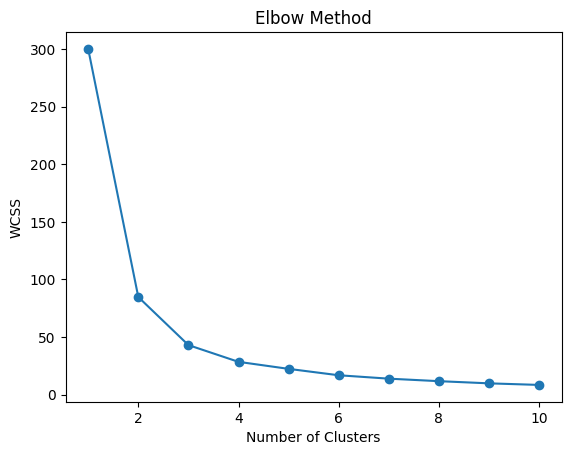

Cluster Centers:
[[ 1.22961906  1.02844019]
 [-1.01511749 -1.22865676]
 [ 0.03665519  0.41744409]]


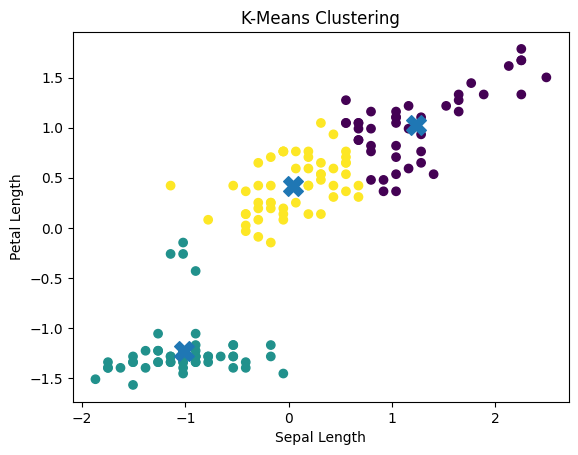

Silhouette Score: 0.5445015264044637


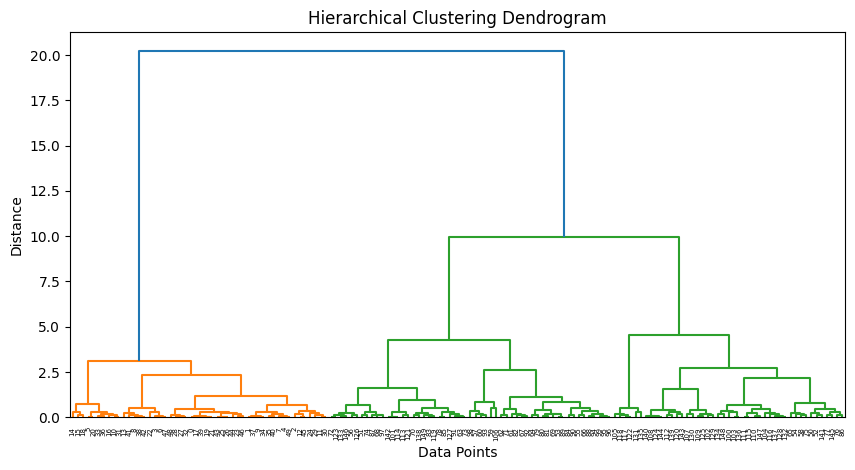

Agglomerative Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 0 2 2 2 0 2 2 2 2 2 2 0 2 2 2 2 2 2 2 2
 2 0 0 0 2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]
Agglomerative Silhouette Score: 0.5359148513088201


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Load dataset
iris = load_iris()

X = pd.DataFrame(
    iris.data[:, [0, 2]],
    columns=["SepalLength", "PetalLength"]
)

# Handle missing values
X = pd.DataFrame(
    SimpleImputer(strategy="mean").fit_transform(X),
    columns=X.columns
)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# Optimal K
k = 3

# 3. K-Means
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X_scaled)

print("Cluster Centers:")
print(kmeans.cluster_centers_)

# Visualize clusters
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis"
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200
)

plt.xlabel("Sepal Length")
plt.ylabel("Petal Length")
plt.title("K-Means Clustering")
plt.show()

# 4. Silhouette Score
score = silhouette_score(X_scaled, labels)

print("Silhouette Score:", score)

# 5. Agglomerative Hierarchical Clustering

# Dendrogram
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
h
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

# Agglomerative clustering
agg = AgglomerativeClustering(
    n_clusters=k,
    linkage="ward"
)

agg_labels = agg.fit_predict(X_scaled)

print("Agglomerative Labels:")
print(agg_labels)

agg_score = silhouette_score(
    X_scaled,
    agg_labels
)

print("Agglomerative Silhouette Score:", agg_score)

Forward Selection:
['bmi', 's5', 'bp', 's3', 'sex', 's1', 's2']

Backward Elimination:
['sex', 'bmi', 'bp', 's1', 's2', 's5']

Best Alpha:
1.9306977288832496

Lasso Coefficients:
age     0.000000
sex    -7.537984
bmi    26.150560
bp     14.797112
s1     -4.214568
s2     -0.000000
s3    -10.911430
s4      0.000000
s5     21.596436
s6      1.521781
dtype: float64

Lasso Selected Features:
['sex', 'bmi', 'bp', 's1', 's3', 's5', 's6']

Zero Coefficient Features:
['age', 's2', 's4']

MSE: 2799.065837459068
R2 Score: 0.47169013453743336

FEATURE COMPARISON
Forward Selection:
['bmi', 's5', 'bp', 's3', 'sex', 's1', 's2']

Backward Elimination:
['sex', 'bmi', 'bp', 's1', 's2', 's5']

Lasso:
['sex', 'bmi', 'bp', 's1', 's3', 's5', 's6']


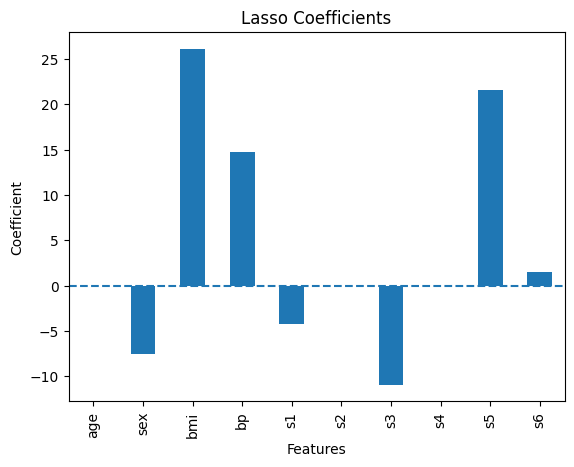

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load dataset
data = load_diabetes()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = pd.Series(data.target)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Scale
scaler = StandardScaler()

X_train = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X.columns
)

X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X.columns
)


# 2. Forward Selection
def forward_selection(X, y):

    selected = []
    remaining = list(X.columns)
    best_score = -np.inf

    while remaining:

        scores = {}

        for feature in remaining:

            features = selected + [feature]

            model = LinearRegression()

            score = cross_val_score(
                model,
                X[features],
                y,
                cv=5,
                scoring="r2"
            ).mean()

            scores[feature] = score

        best_feature = max(scores, key=scores.get)

        if scores[best_feature] > best_score:

            selected.append(best_feature)
            remaining.remove(best_feature)

            best_score = scores[best_feature]

        else:
            break

    return selected


forward_features = forward_selection(
    X_train,
    y_train
)

print("Forward Selection:")
print(forward_features)


# 3. Backward Elimination
def backward_elimination(X, y):

    selected = list(X.columns)
    model = LinearRegression()

    best_score = cross_val_score(
        model,
        X[selected],
        y,
        cv=5,
        scoring="r2"
    ).mean()

    while len(selected) > 1:

        scores = {}

        for feature in selected:

            features = [
                f for f in selected
                if f != feature
            ]

            score = cross_val_score(
                model,
                X[features],
                y,
                cv=5,
                scoring="r2"
            ).mean()

            scores[feature] = score

        remove_feature = max(
            scores,
            key=scores.get
        )

        new_score = scores[remove_feature]

        if new_score >= best_score:

            selected.remove(remove_feature)
            best_score = new_score

        else:
            break

    return selected


backward_features = backward_elimination(
    X_train,
    y_train
)

print("\nBackward Elimination:")
print(backward_features)


# 4. Lasso Regression

params = {
    "alpha": np.logspace(-4, 2, 50)
}

lasso = Lasso(max_iter=10000)

grid = GridSearchCV(
    lasso,
    params,
    cv=5,
    scoring="r2"
)

grid.fit(X_train, y_train)

best_lasso = grid.best_estimator_

print("\nBest Alpha:")
print(grid.best_params_["alpha"])


# Lasso coefficients
coefficients = pd.Series(
    best_lasso.coef_,
    index=X.columns
)

print("\nLasso Coefficients:")
print(coefficients)


# Selected features
lasso_features = coefficients[
    coefficients != 0
].index.tolist()

print("\nLasso Selected Features:")
print(lasso_features)


# Features whose coefficients became zero
zero_features = coefficients[
    coefficients == 0
].index.tolist()

print("\nZero Coefficient Features:")
print(zero_features)


# 5. Test performance
y_pred = best_lasso.predict(X_test)

mse = mean_squared_error(
    y_test,
    y_pred
)

r2 = r2_score(
    y_test,
    y_pred
)

print("\nMSE:", mse)
print("R2 Score:", r2)


# 6. Compare all methods
print("\n==============================")
print("FEATURE COMPARISON")
print("==============================")

print("Forward Selection:")
print(forward_features)

print("\nBackward Elimination:")
print(backward_features)

print("\nLasso:")
print(lasso_features)


# Lasso coefficient plot
coefficients.plot(kind="bar")

plt.axhline(0, linestyle="--")
plt.title("Lasso Coefficients")
plt.xlabel("Features")
plt.ylabel("Coefficient")
plt.show()